# Olist P02A: Tiền xử lý dữ liệu

## Thứ tự chạy
1. Thiết lập và nạp 8 bảng nguồn.
2. Kiểm tra fan-out bằng join thô.
3. Dựng bảng đúng grain `order_id + order_item_id`.
4. Lọc đơn delivered, gộp payment và review.
5. Tạo biến, xử lý thiếu và ngoại lệ.
6. Chạy kiểm tra tự động, xuất dữ liệu và hình tổng quan.

**Kết quả kỳ vọng từ lần chạy kiểm tra:** 110.187 dòng × 40 cột, 96.468 đơn delivered, không trùng cặp order-item.

# Cài đặt


In [2]:
# ===== TIỀN XỬ LÝ + TRỰC QUAN HOÁ QUÁ TRÌNH TIỀN XỬ LÝ =====
# Nguyên tắc: (1) dựng bảng ĐÚNG GRAIN (1 dòng = 1 order item) NGAY TỪ ĐẦU, không join thô rồi sửa sau;
#             (2) mỗi bước đều ghi vào nhật ký `log` để vẽ funnel; (3) có kiểm tra tự động cuối script.
# NOTE: CHẠY CẢ FILE (bỏ bôi đen rồi bấm Run). Bôi đen một đoạn rồi Run → Code Runner chạy file tạm tempCodeRunnerFile.py, thiếu import/biến → NameError.


import os, sys
from pathlib import Path
BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
os.chdir(BASE)                                                        # thư mục làm việc = thư mục chứa script
try: sys.stdout.reconfigure(encoding='utf-8')                         # in tiếng Việt trên console Windows
except Exception: pass
# >>> Nếu data nằm chỗ khác, sửa đường dẫn thư mục chứa 8 file CSV ở đây (hoặc đặt biến môi trường OLIST_DATA):
DATA_DIR_OVERRIDE = ''
def find_data_dir(required='olist_orders_dataset.csv'):
    home = Path.home()
    cands = [DATA_DIR_OVERRIDE, os.environ.get('OLIST_DATA'), BASE / 'data', BASE, BASE.parent / 'data', BASE.parent,
             home / 'Downloads' / 'final_code' / 'data', home / 'Downloads' / 'final_code', home / 'Downloads' / 'data', home / 'Downloads' / 'raw_olist', home / 'Downloads']
    for c in cands:
        if c and (Path(c) / required).exists(): return str(Path(c)) + os.sep
    for p in BASE.rglob(required): return str(p.parent) + os.sep   # tìm đệ quy trong thư mục dự án
    raise FileNotFoundError(f'Không tìm thấy {required}. Chép 8 CSV Olist vào {BASE / "data"} hoặc sửa DATA_DIR_OVERRIDE ở đầu file.\n'
                            'Đã tìm ở: ' + '; '.join(str(c) for c in cands if c))

import pandas as pd, numpy as np, matplotlib, textwrap
import matplotlib.pyplot as plt
D = find_data_dir(); print('Đọc dữ liệu từ:', D)
print('Results will display in the notebook; no separate output folder is created.')


Đọc dữ liệu từ: C:\Users\ttranhan\Downloads\raw_olist\
Results will display in the notebook; no separate output folder is created.


## 0. Nạp dữ liệu

Đọc 8 bảng nguồn và chuyển các cột thời gian sang kiểu datetime.

**Đầu vào:** Orders, order items, customers, sellers, products, category translation, payments, reviews.

**Đầu ra:** Các DataFrame nguồn và bảng tỷ lệ thiếu trước xử lý.

**Điểm cần kiểm tra sau khi chạy:**
- Kiểm tra số dòng từng bảng.
- Kiểm tra các cột ngày không bị đọc thành text.

> **Lưu ý:** Bảng geolocation không được dùng trong bước này.

In [3]:
# ---------- 0. Nạp dữ liệu ----------
orders = pd.read_csv(D+'olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp','order_approved_at',
          'order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date'])
items = pd.read_csv(D+'olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
customers = pd.read_csv(D+'olist_customers_dataset.csv'); sellers = pd.read_csv(D+'olist_sellers_dataset.csv')
products = pd.read_csv(D+'olist_products_dataset.csv'); trans = pd.read_csv(D+'product_category_name_translation.csv')
payments = pd.read_csv(D+'olist_order_payments_dataset.csv')
reviews = pd.read_csv(D+'olist_order_reviews_dataset.csv', parse_dates=['review_creation_date','review_answer_timestamp'])
products = products.merge(trans, on='product_category_name', how='left')      # thêm tên category tiếng Anh

log = []                                   # nhật ký: (bước, số dòng, ghi chú)
def step(name, n, note=''): log.append((name, n, note))
print('Input row counts:', {name: table.shape[0] for name, table in {'orders': orders, 'items': items, 'customers': customers, 'sellers': sellers, 'products': products, 'payments': payments, 'reviews': reviews}.items()})


Input row counts: {'orders': 99441, 'items': 112650, 'customers': 99441, 'sellers': 3095, 'products': 32951, 'payments': 103886, 'reviews': 99224}


## Bước 0: join thô → bị fan-out

Minh họa lỗi nhân dòng khi nối trực tiếp payments và reviews vào bảng chi tiết đơn hàng.

**Đầu vào:** Các DataFrame nguồn.

**Đầu ra:** `naive`, số dòng join thô và `GMV_naive`.

**Điểm cần kiểm tra sau khi chạy:**
- Số dòng lớn hơn grain đúng.
- GMV join thô cao hơn GMV gốc.

> **Lưu ý:** Đây là phép kiểm tra chẩn đoán, không dùng `naive` làm dữ liệu cuối.

In [4]:
# ---------- Bước 0: join thô → bị fan-out ----------
naive = orders.merge(items, on='order_id').merge(payments, on='order_id', how='left').merge(reviews, on='order_id', how='left')
step('0. Join thô orders+items+payments+reviews', len(naive), 'bị fan-out — chỉ để so sánh, KHÔNG dùng')
GMV_naive    = naive.query("order_status=='delivered'").price.sum()
GMV_true_raw = items.merge(orders[['order_id','order_status']], on='order_id').query("order_status=='delivered'").price.sum()
print(f'Raw join: {len(naive):,} rows | GMV raw join: {GMV_naive:,.2f} | GMV from original items: {GMV_true_raw:,.2f}')


Raw join: 118,310 rows | GMV raw join: 13,876,471.73 | GMV from original items: 13,221,498.11


## Bước 1: dựng bảng đúng grain (1 dòng = 1 order item)

Dựng bảng nền tại đúng độ hạt order item trước khi nối bảng có quan hệ một-nhiều.

**Đầu vào:** Orders, items, customers, sellers, products, translation.

**Đầu ra:** DataFrame `df` với mỗi dòng là một `order_id + order_item_id`.

**Điểm cần kiểm tra sau khi chạy:**
- `duplicated([order_id, order_item_id])` phải bằng 0.
- GMV phải khớp bảng order items gốc.

> **Lưu ý:** Đúng grain là điều kiện quan trọng nhất để tránh sai doanh thu và sai tỷ trọng.

In [19]:
# ---------- Bước 1: dựng bảng đúng grain (1 dòng = 1 order item) ----------
df = (orders.merge(items, on='order_id', how='inner')
            .merge(customers, on='customer_id', how='left')
            .merge(sellers, on='seller_id', how='left')
            .merge(products, on='product_id', how='left'))
step('1. Orders vs Items vs Customer vs Seller vs Product (đúng grain)', len(df))
df_step1 = df.copy()     # giữ bản MỌI trạng thái đơn → dùng cho Data Warehouse (Dim_OrderStatus) và đặc trưng cancel_rate
# 8 trạng thái Olist gom thành 3 nhóm (base cho dim_orderstatus của DW)
STATUS_GROUP = {'delivered': 'Completed',
                'created': 'In progress', 'approved': 'In progress', 'invoiced': 'In progress', 'processing': 'In progress', 'shipped': 'In progress',
                'canceled': 'Failed', 'unavailable': 'Failed'}
print(f'Step 1: {len(df):,} rows x {df.shape[1]} columns; first 5 rows:\n{df.head().to_string(index=False)}')


Step 1: 112,650 rows x 30 columns; first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13                    2017-10-18              1 87285b34884572647811a353c7ac498a 3504c0cb

## Bước 2: chỉ giữ đơn đã hoàn tất

Tạo lát cắt delivered cho phân tích doanh thu, giao hàng và review thực nhận.

**Đầu vào:** Bảng đúng grain ở bước 1.

**Đầu ra:** `df` chỉ còn order_status = delivered.

**Điểm cần kiểm tra sau khi chạy:**
- So sánh số dòng trước và sau lọc.
- Không dùng canceled hoặc in-progress để tính delivery_days.

> **Lưu ý:** Bảng mọi trạng thái sẽ được tạo riêng cho Data Warehouse ở bước sau.

In [20]:
# ---------- Bước 2: chỉ giữ đơn đã hoàn tất ----------
df = df[df.order_status == 'delivered'].copy()
step('2. Chỉ giữ đơn delivered', len(df))
print(f'Step 2 delivered orders: {len(df):,} rows; first 5 rows:\n{df.head().to_string(index=False)}')


Step 2 delivered orders: 110,197 rows; first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13                    2017-10-18              1 87285b34884572647811a353c7ac498a 3504

## Bước 3: gộp payment (SUM) + khử trùng review TRƯỚC khi nối → hết fan-out

Gộp payment về mức order và giữ review mới nhất trước khi nối vào bảng order item.

**Đầu vào:** Payments và reviews thô.

**Đầu ra:** Các cột payment tổng hợp, loại payment chính, review duy nhất trên mỗi order.

**Điểm cần kiểm tra sau khi chạy:**
- Số dòng của `df` không thay đổi sau join.
- Mỗi order chỉ có một review được chọn.

> **Lưu ý:** Một đơn có thể có nhiều payment hoặc review; phải tổng hợp trước khi nối.

In [21]:
# ---------- Bước 3: gộp payment (SUM) + khử trùng review TRƯỚC khi nối → hết fan-out ----------
payment_agg = (payments.sort_values('payment_value', ascending=False).groupby('order_id')
    .agg(total_payment_value=('payment_value', 'sum'), n_payment_methods=('payment_type', 'nunique'),
         max_installments=('payment_installments', 'max'),
         main_payment_type=('payment_type', 'first')      # phương thức có giá trị lớn nhất trong đơn
         ).reset_index())
reviews_dedup = reviews.sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')   # giữ review mới nhất
df = (df.merge(payment_agg, on='order_id', how='left')
        .merge(reviews_dedup[['order_id', 'review_score']], on='order_id', how='left'))
step('3. Gộp payment (SUM) + khử trùng review (giữ mới nhất)', len(df), 'không đổi số dòng => hết fan-out')
GMV_fixed = df.price.sum()
print(f'Step 3: {len(df):,} rows | GMV: {GMV_fixed:,.2f} | first 5 rows:\n{df.head().to_string(index=False)}')


Step 3: 110,197 rows | GMV: 13,221,498.11 | first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english  total_payment_value  n_payment_methods  max_installments main_payment_type  review_score
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10

## Bước 4: xử lý thiếu + tạo cột dẫn xuất

Xử lý danh mục thiếu, tính ngày giao, độ trễ, cờ giao trễ và các biến thời gian phục vụ EDA.

**Đầu vào:** Bảng delivered đã nối payment và review.

**Đầu ra:** Các cột `delivery_days`, `delay_days`, `is_late`, các thuộc tính tháng/ngày/giờ.

**Điểm cần kiểm tra sau khi chạy:**
- Kiểm tra tỷ lệ thiếu sau tạo biến.
- Kiểm tra delivery_days không âm bất thường trước khi lọc.

> **Lưu ý:** Review chưa được điền ở bước này để giữ log thiếu trước/sau.

In [22]:
# ---------- Bước 4: xử lý thiếu + tạo cột dẫn xuất ----------
CHECK_COLS = ['product_category_name_english', 'review_score', 'order_delivered_customer_date']
miss_before = df[CHECK_COLS].isna().mean() * 100
df['product_category_name_english'] = df['product_category_name_english'].fillna('unknown')   # category thiếu → 'unknown'
df['delivery_days']   = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df['estimated_days']  = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df['is_late']         = (df.order_delivered_customer_date > df.order_estimated_delivery_date).astype(int)
df['freight_ratio']   = df.freight_value / df.price
df['total_item_value'] = df.price + df.freight_value
dd_before = df.delivery_days.copy()                       # để vẽ phân phối TRƯỚC xử lý outlier
df = df.dropna(subset=['delivery_days'])                  # đơn 'delivered' nhưng thiếu ngày giao: không impute (là biến nghiệp vụ chính)
step('4. Bỏ dòng thiếu ngày giao', len(df))
print('Step 4 missing values before (%) and sample rows:\n', miss_before.round(2).to_string(), '\n', df.head().to_string(index=False))


Step 4 missing values before (%) and sample rows:
 product_category_name_english    1.41
review_score                     0.75
order_delivered_customer_date    0.01 
                         order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english  total_payment_value  n_payment_methods  max_installments main_payment_type  review_score  delivery_days  estimated_days  is_late  freight_ratio  total

## Bước 5: loại outlier delivery_days

Chỉ loại các giá trị ngày giao không hợp lệ ngoài khoảng [0, 200].

**Đầu vào:** `delivery_days`.

**Đầu ra:** Bảng không còn giá trị ngày giao âm hoặc quá 200 ngày.

**Điểm cần kiểm tra sau khi chạy:**
- Số dòng bị loại phải rất nhỏ.
- Không dùng IQR vì các đơn giao chậm hợp lệ là tín hiệu nghiệp vụ quan trọng.

> **Lưu ý:** Khoảng [0,200] là quy tắc hợp lệ dữ liệu, không phải cắt đuôi thống kê.

In [23]:
# ---------- Bước 5: loại outlier delivery_days ----------
df = df[(df.delivery_days >= 0) & (df.delivery_days <= 200)].copy()     # âm = lỗi nhập; >200 ngày = bất thường
step('5. Loại outlier delivery_days ∉ [0,200]', len(df))
print(f'Step 5 after outlier removal: {len(df):,} rows; first 5 rows:\n{df.head().to_string(index=False)}')


Step 5 after outlier removal: 110,187 rows; first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english  total_payment_value  n_payment_methods  max_installments main_payment_type  review_score  delivery_days  estimated_days  is_late  freight_ratio  total_item_value
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10

## Bước 6: chuẩn hoá text + impute review_score

Chuẩn hóa chuỗi và điền điểm review thiếu bằng trung vị để hoàn tất dữ liệu sạch.

**Đầu vào:** Các cột danh mục, thành phố, bang và review_score.

**Đầu ra:** Bảng `df` hoàn chỉnh, không thiếu các trường phân tích cốt lõi.

**Điểm cần kiểm tra sau khi chạy:**
- Review sau điền phải nằm trong 1–5.
- Danh mục thiếu phải thành `unknown`.

> **Lưu ý:** Cần ghi nhận cách điền review khi trình bày hạn chế nghiên cứu.

In [24]:
# ---------- Bước 6: chuẩn hoá text + impute review_score ----------
df['customer_city'] = df.customer_city.str.strip().str.title()
df['seller_city']   = df.seller_city.str.strip().str.title()
df['review_score']  = df.review_score.fillna(df.review_score.median())   # impute trung vị
step('6. Chuẩn hoá text + impute review_score (median)', len(df))
miss_after = df[['product_category_name_english', 'review_score', 'delivery_days']].isna().mean() * 100
print('Step 6 missing values after (%):\n', miss_after.round(2).to_string(), '\nFirst 5 rows:\n', df.head().to_string(index=False))


Step 6 missing values after (%):
 product_category_name_english    0.0
review_score                     0.0
delivery_days                    0.0 
First 5 rows:
                         order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english  total_payment_value  n_payment_methods  max_installments main_payment_type  review_score  delivery_days  estimated_days  is_late  freight_ratio  total_item_

## Kiểm tra tự động (chạy sai là dừng ngay)

Chạy các assert để xác nhận grain, thiếu dữ liệu, khoảng giá trị và đối chiếu GMV.

**Đầu vào:** Bảng đã xử lý.

**Đầu ra:** Thông báo kiểm tra đạt; script dừng ngay nếu có sai lệch.

**Điểm cần kiểm tra sau khi chạy:**
- Trùng order-item bằng 0.
- GMV đúng grain khớp dữ liệu nguồn.
- Các biến chính không thiếu.

> **Lưu ý:** Không bỏ qua cell này trước khi xuất dữ liệu.

In [25]:
# ---------- Kiểm tra tự động (chạy sai là dừng ngay) ----------
assert df.duplicated(['order_id', 'order_item_id']).sum() == 0, 'còn trùng grain → vẫn fan-out'
assert (df.order_status == 'delivered').all()
assert df[['price', 'freight_value', 'delivery_days', 'review_score']].notna().all().all(), 'còn NaN ở cột then chốt'
assert GMV_fixed <= GMV_true_raw + 1e-6 and GMV_fixed < GMV_naive, 'GMV sau xử lý phải ≤ GMV gốc và < GMV join thô'
print('All automatic validation checks passed.')


All automatic validation checks passed.


## Sau tiền xử lý, tạo file csv lưu trữ với tên: olist_preprocessed
Bảng final được lưu ở: Downloads/olist_preprocessed.csv


In [26]:
CSV_PATH = Path.home() / 'Downloads' / 'olist_preprocessed.csv'
df.to_csv(CSV_PATH, index=False, encoding='utf-8-sig')
print(f'Processed delivered data: {len(df):,} rows x {df.shape[1]} columns')
print(f'CSV saved to: {CSV_PATH}')
display(df)
print('Processing log:\n', pd.DataFrame(log, columns=['Step', 'Rows', 'Note']).to_string(index=False))

Processed delivered data: 110,187 rows x 40 columns
CSV saved to: C:\Users\ttranhan\Downloads\olist_preprocessed.csv


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,total_payment_value,n_payment_methods,max_installments,main_payment_type,review_score,delivery_days,estimated_days,is_late,freight_ratio,total_item_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,38.71,2.0,1.0,voucher,4.0,8.436574,15.544063,0,0.290764,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,141.46,1.0,1.0,boleto,4.0,13.782037,19.137766,0,0.191744,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,179.12,1.0,3.0,credit_card,5.0,9.394213,26.639711,0,0.120200,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,72.20,1.0,1.0,credit_card,5.0,13.208750,26.188819,0,0.604444,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,28.62,1.0,1.0,credit_card,5.0,2.873877,12.112049,0,0.438191,28.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110192,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,1,f1d4ce8c6dd66c47bbaa8c6781c2a923,...,195.00,1.0,3.0,credit_card,4.0,22.193727,23.459051,0,0.114923,195.00
110193,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,1,b80910977a37536adeddd63663f916ad,...,271.01,1.0,5.0,credit_card,5.0,24.859421,30.384225,0,0.315646,271.01
110194,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,1,d1c427060a0f73f6b889a5c7c61f2ac4,...,441.16,1.0,4.0,credit_card,2.0,17.086424,37.105243,0,0.225513,220.58
110195,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2,d1c427060a0f73f6b889a5c7c61f2ac4,...,441.16,1.0,4.0,credit_card,2.0,17.086424,37.105243,0,0.225513,220.58


Processing log:
                                                             Step   Rows                                    Note
                       0. Join thô orders+items+payments+reviews 118310 bị fan-out — chỉ để so sánh, KHÔNG dùng
    1. Orders ⋈ Items ⋈ Customer ⋈ Seller ⋈ Product (đúng grain) 112650                                        
                                        2. Chỉ giữ đơn delivered 110197                                        
          3. Gộp payment (SUM) + khử trùng review (giữ mới nhất) 110197        không đổi số dòng => hết fan-out
                                      4. Bỏ dòng thiếu ngày giao 110189                                        
                         5. Loại outlier delivery_days ∉ [0,200] 110187                                        
                6. Chuẩn hoá text + impute review_score (median) 110187                                        
1. Orders vs Items vs Customer vs Seller vs Product (đúng grain) 112650                

## Inline all-status summary
The next cell displays a sample of `df_all` and the summary grouped by order status.


In [27]:
# ---------- BẢNG MỌI TRẠNG THÁI (cho DW): Completed = bảng đã làm sạch ở trên; In progress / Failed = nối payment, review, KHÔNG tính delivery_days/is_late ----------
assert set(df_step1.order_status.unique()) <= set(STATUS_GROUP), f'Trạng thái lạ: {set(df_step1.order_status.unique()) - set(STATUS_GROUP)}'
nd = (df_step1[df_step1.order_status != 'delivered']
        .merge(payment_agg, on='order_id', how='left').merge(reviews_dedup[['order_id', 'review_score']], on='order_id', how='left').copy())
nd['product_category_name_english'] = nd['product_category_name_english'].fillna('unknown')
nd['customer_city'] = nd.customer_city.str.strip().str.title(); nd['seller_city'] = nd.seller_city.str.strip().str.title()
nd['estimated_days'] = (nd.order_estimated_delivery_date - nd.order_purchase_timestamp).dt.total_seconds() / 86400
nd['delivery_days'] = np.nan; nd['is_late'] = np.nan                       # chưa/không giao thành công → không có chất lượng giao hàng
nd['freight_ratio'] = nd.freight_value / nd.price; nd['total_item_value'] = nd.price + nd.freight_value
df_all = pd.concat([df, nd], ignore_index=True)
df_all['status_group'] = df_all.order_status.map(STATUS_GROUP)
assert df_all.duplicated(['order_id', 'order_item_id']).sum() == 0 and len(df_all) == len(df) + len(nd)
status_summary = (df_all.groupby(['status_group', 'order_status']).agg(n_orders=('order_id', 'nunique'), n_items=('order_id', 'size'), gmv=('price', 'sum')).reset_index())
print('Status counts:\n', df_all.groupby(['status_group', 'order_status']).size().to_string())
print(f'All statuses: {len(df_all):,} rows x {df_all.shape[1]} columns; first 5 rows:\n{df_all.head().to_string(index=False)}')
print('Status summary:\n', status_summary.to_string(index=False))


Status counts:
 status_group  order_status
Completed     delivered       110187
Failed        canceled           542
              unavailable          7
In progress   approved             3
              invoiced           359
              processing         357
              shipped           1185
All statuses: 112,640 rows x 41 columns; first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_

## ALIAS cho phần Descriptive Analysis bên dưới

Tạo alias `df_delivered` trỏ đến bảng sạch, nhưng notebook EDA riêng sẽ đọc pickle thay vì phụ thuộc bộ nhớ hiện tại.

**Đầu vào:** DataFrame `df`.

**Đầu ra:** Biến `df_delivered`.

**Điểm cần kiểm tra sau khi chạy:**
- Xác nhận alias có cùng số dòng với `df`.

> **Lưu ý:** Cell này giúp tương thích với script gốc.

In [28]:
# ---------- ALIAS cho phần Descriptive Analysis bên dưới ----------
# Phần phân tích mô tả (2.3) dùng tên `df_delivered` = bảng ĐÃ tiền xử lý (đúng grain, 1 dòng = 1 order item).
# Trong script này bảng đó đang tên `df` → gán alias (không copy thêm bộ nhớ). Nếu thiếu dòng này sẽ báo: NameError: name 'df_delivered' is not defined
df_delivered = df
print(f'df_delivered is ready: {df_delivered.shape[0]:,} rows x {df_delivered.shape[1]} columns; first 5 rows:\n{df_delivered.head().to_string(index=False)}')


df_delivered is ready: 110,187 rows x 40 columns; first 5 rows:
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  order_item_id                       product_id                        seller_id shipping_limit_date  price  freight_value               customer_unique_id  customer_zip_code_prefix           customer_city customer_state  seller_zip_code_prefix     seller_city seller_state product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm product_category_name_english  total_payment_value  n_payment_methods  max_installments main_payment_type  review_score  delivery_days  estimated_days  is_late  freight_ratio  total_item_value
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10

## Inline visualization
The next cell displays the chart and missing-value summary directly in the notebook.


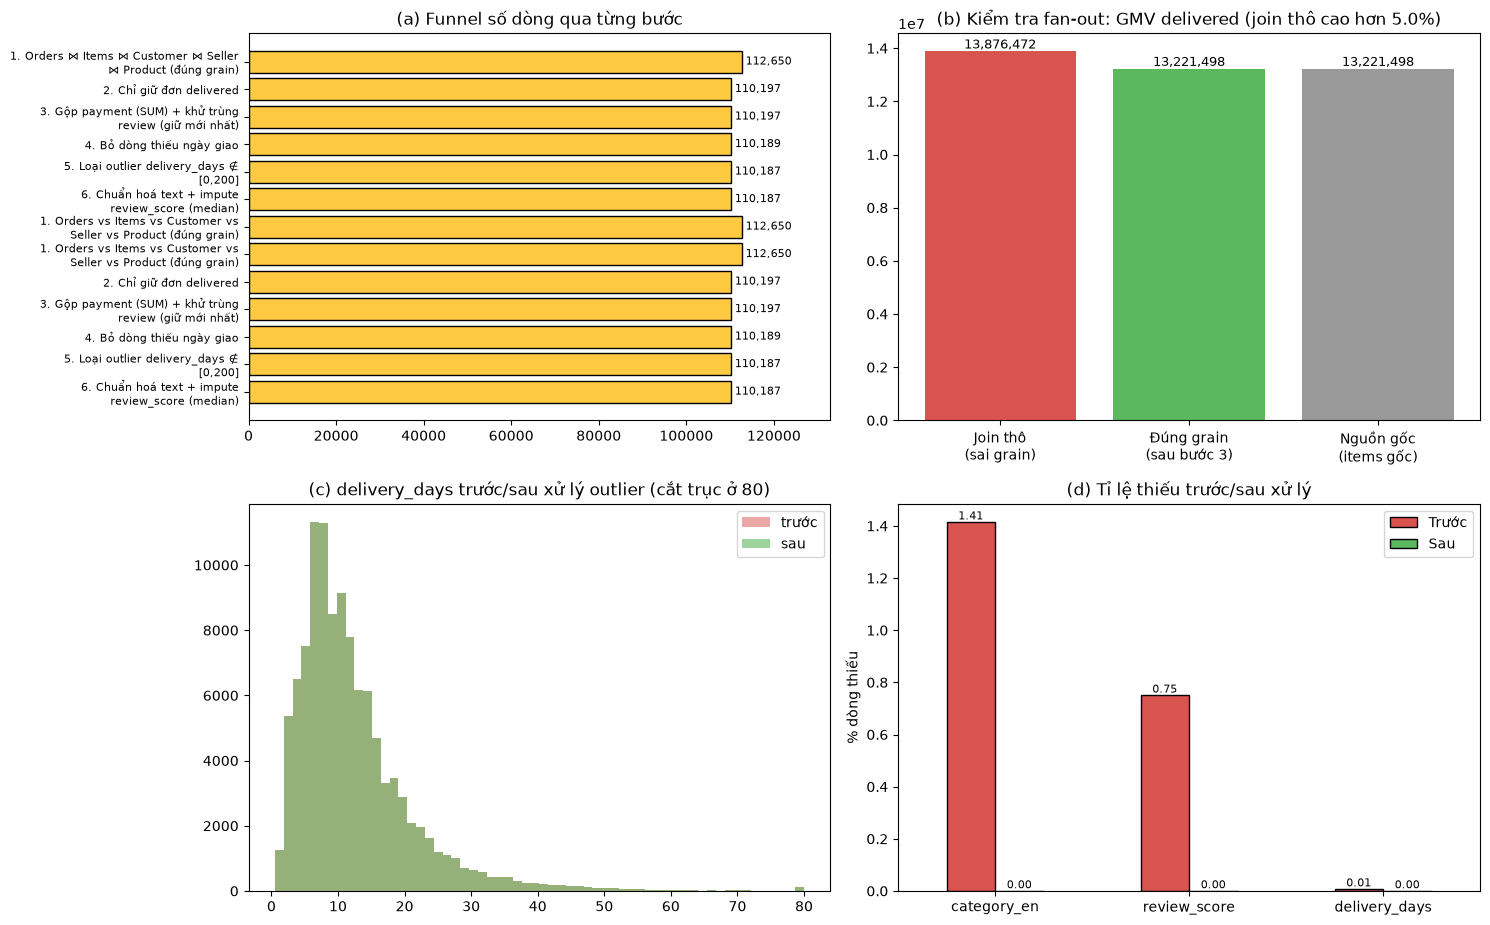

                                                            Bước  Số dòng                                 Ghi chú
                       0. Join thô orders+items+payments+reviews   118310 bị fan-out — chỉ để so sánh, KHÔNG dùng
    1. Orders ⋈ Items ⋈ Customer ⋈ Seller ⋈ Product (đúng grain)   112650                                        
                                        2. Chỉ giữ đơn delivered   110197                                        
          3. Gộp payment (SUM) + khử trùng review (giữ mới nhất)   110197        không đổi số dòng => hết fan-out
                                      4. Bỏ dòng thiếu ngày giao   110189                                        
                         5. Loại outlier delivery_days ∉ [0,200]   110187                                        
                6. Chuẩn hoá text + impute review_score (median)   110187                                        
1. Orders vs Items vs Customer vs Seller vs Product (đúng grain)   112650               

In [29]:
# ---------- TRỰC QUAN HOÁ (4 panel) ----------
fig, ax = plt.subplots(2, 2, figsize=(15, 9.5)); ax = ax.ravel()
names = [l[0] for l in log[1:]]; vals = [l[1] for l in log[1:]]            # bỏ bước 0 (chỉ minh chứng)
ax[0].barh(range(len(vals))[::-1], vals, color='#FFCA41', edgecolor='k')
ax[0].set_yticks(range(len(vals))[::-1]); ax[0].set_yticklabels([textwrap.fill(n, 38) for n in names], fontsize=8)
for i, v in enumerate(vals): ax[0].text(v, len(vals)-1-i, f' {v:,}', va='center', fontsize=8)
ax[0].set_title('(a) Funnel số dòng qua từng bước'); ax[0].set_xlim(0, max(vals)*1.18)
G = [GMV_naive, GMV_fixed, GMV_true_raw]
ax[1].bar(['Join thô\n(sai grain)', 'Đúng grain\n(sau bước 3)', 'Nguồn gốc\n(items gốc)'], G, color=['#d9534f', '#5cb85c', '#999'])
for i, v in enumerate(G): ax[1].text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax[1].set_title(f'(b) Kiểm tra fan-out: GMV delivered (join thô cao hơn {GMV_naive/GMV_true_raw-1:.1%})')
ax[2].hist(dd_before.dropna().clip(lower=-10, upper=80), bins=60, alpha=.5, label='trước', color='#d9534f')
ax[2].hist(df.delivery_days.clip(upper=80), bins=60, alpha=.6, label='sau', color='#5cb85c')
ax[2].set_title('(c) delivery_days trước/sau xử lý outlier (cắt trục ở 80)'); ax[2].legend()
mm = pd.DataFrame({'Trước': miss_before.values, 'Sau': [0.0, 0.0, 0.0]}, index=['category_en', 'review_score', 'delivery_days'])
mm.loc['delivery_days', 'Trước'] = dd_before.isna().mean() * 100
mm.loc['delivery_days', 'Sau'] = miss_after['delivery_days']; mm.loc['category_en', 'Sau'] = miss_after['product_category_name_english']; mm.loc['review_score', 'Sau'] = miss_after['review_score']
mm.plot.bar(ax=ax[3], color=['#d9534f', '#5cb85c'], edgecolor='k'); ax[3].set_ylabel('% dòng thiếu'); ax[3].tick_params(axis='x', rotation=0)
for c in ax[3].containers: ax[3].bar_label(c, fmt='%.2f', fontsize=8)
ax[3].set_title('(d) Tỉ lệ thiếu trước/sau xử lý')
plt.tight_layout(); plt.show()

print(pd.DataFrame(log, columns=['Bước', 'Số dòng', 'Ghi chú']).to_string(index=False))
print(f"\nGMV join thô={GMV_naive:,.0f} | đúng grain={GMV_fixed:,.0f} | gốc={GMV_true_raw:,.0f}")
print("Missing % trước:\n", miss_before.round(2).to_string()); print("Missing % sau:\n", miss_after.round(2).to_string())
print("duplicated(order_id,order_item_id):", df.duplicated(['order_id', 'order_item_id']).sum())
print('Missing values before/after (%):\n', mm.round(3).to_string())
print('The four-panel chart is displayed above in this notebook.')


## Ghi chú giải thích nghiệp vụ

Cell chỉ chứa chú thích nghiệp vụ của script gốc.

**Đầu vào:** Không có.

**Đầu ra:** Không tạo biến mới.

**Điểm cần kiểm tra sau khi chạy:**
Đọc để hiểu vì sao phải tổng hợp payment, giữ delivered và kiểm soát grain.

> **Lưu ý:** Có thể bỏ qua khi chạy; phần này không thay đổi dữ liệu.

In [ ]:
# ---------- Ghi chú giải thích nghiệp vụ  ---------- #
# - Vì sao gộp payment trước khi join: tránh "fan-out" (Join sai grain) — đơn trả góp qua 2 thẻ sẽ bị đếm 2 lần nếu join trực tiếp.
# - Vì sao dựng đúng grain ngay từ đầu: nếu join thô payments/reviews, `price` bị cộng nhiều lần, mọi số liệu doanh thu và
#   `avg_review` của seller ở các mục sau đều sai. Kiểm tra: df.duplicated(['order_id','order_item_id']).sum() phải bằng 0.
# - Vì sao chỉ giữ order_status == 'delivered': đơn huỷ/đang giao có ý nghĩa nghiệp vụ khác, không trộn khi tính doanh thu/review thực nhận.
print('Business note: aggregate payments and deduplicate reviews before joining to avoid fan-out and inflated GMV.')


## Results
- Cleaned delivered data remains in `df` / `df_delivered` in the current kernel.
- All-order-status data remains in `df_all`.
- The processing log remains in `log`; tables and charts are displayed in notebook outputs.
